In [1]:
<style>
div.cell {
    margin-top: 5px;
    margin-bottom: 5px;
}
</style>

import pandas as pd
import yfinance as yf
import mplfinance as mpf

In [5]:
#input parameters 
ticker_symbol = 'RELIANCE.NS'     #or 'RELIANCE.NS'
start_date = '2026-01-01'
end_date ='2026-02-15'
#Download historical data
data = yf.download(ticker_symbol , start=start_date , end=end_date , auto_adjust =False , actions = False)
print(data)

[*********************100%***********************]  1 of 1 completed

Price         Adj Close        Close         High          Low         Open  \
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS   
Date                                                                          
2026-01-01  1575.599976  1575.599976  1592.500000  1571.099976  1573.699951   
2026-01-02  1592.300049  1592.300049  1594.599976  1578.199951  1580.000000   
2026-01-05  1578.099976  1578.099976  1611.800049  1575.300049  1593.000000   
2026-01-06  1507.599976  1507.599976  1569.000000  1496.300049  1569.000000   
2026-01-07  1504.199951  1504.199951  1520.000000  1498.000000  1510.000000   
2026-01-08  1470.599976  1470.599976  1503.900024  1468.800049  1500.000000   
2026-01-09  1475.300049  1475.300049  1479.900024  1465.000000  1465.000000   
2026-01-12  1483.199951  1483.199951  1485.300049  1451.000000  1475.300049   
2026-01-13  1452.800049  1452.800049  1485.800049  1444.699951  1485.000000   
2026-01-14  1458.800049  1458.800049  1467.000000  1

In [6]:
print(data.columns)

MultiIndex([('Adj Close', 'RELIANCE.NS'),
            (    'Close', 'RELIANCE.NS'),
            (     'High', 'RELIANCE.NS'),
            (      'Low', 'RELIANCE.NS'),
            (     'Open', 'RELIANCE.NS'),
            (   'Volume', 'RELIANCE.NS')],
           names=['Price', 'Ticker'])


In [7]:
#Flattened multi-level column index if present 
if isinstance(data.columns , pd.MultiIndex):
    data.columns = [col[0] if isinstance(col , tuple) else col for col in data.columns]
print(data.columns)

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


In [8]:
#Keep only necessary columns
ohlc_cols = ['Open','High','Low','Close','Volume']
data = data[ohlc_cols]
print(data)

                   Open         High          Low        Close    Volume
Date                                                                    
2026-01-01  1573.699951  1592.500000  1571.099976  1575.599976   6408128
2026-01-02  1580.000000  1594.599976  1578.199951  1592.300049   6602230
2026-01-05  1593.000000  1611.800049  1575.300049  1578.099976   8704973
2026-01-06  1569.000000  1569.000000  1496.300049  1507.599976  27417125
2026-01-07  1510.000000  1520.000000  1498.000000  1504.199951  11199340
2026-01-08  1500.000000  1503.900024  1468.800049  1470.599976  16518684
2026-01-09  1465.000000  1479.900024  1465.000000  1475.300049   8335311
2026-01-12  1475.300049  1485.300049  1451.000000  1483.199951   8883745
2026-01-13  1485.000000  1485.800049  1444.699951  1452.800049  13499760
2026-01-14  1444.000000  1467.000000  1440.199951  1458.800049   8321764
2026-01-15  1458.800049  1458.800049  1458.800049  1458.800049         0
2026-01-16  1458.800049  1480.000000  1455.099976  

In [10]:
#Ensure all data is numeric and drop invalid rows
data = data.apply(pd.to_numeric).dropna()

print("\n Final columns dtypes:")
print(data.dtypes)


 Final columns dtypes:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


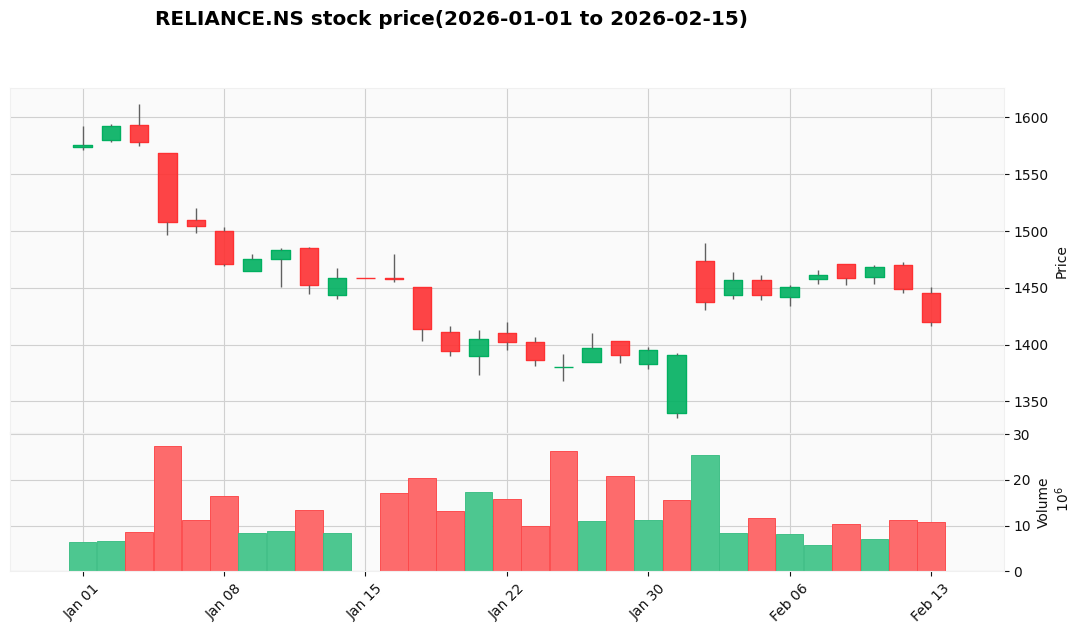

In [11]:
#plot candlestick with volume
mpf.plot(
    data,
    type = 'candle',
    volume =True,
    title = f'{ticker_symbol} stock price({start_date} to {end_date})',
    ylabel = 'Price',
    ylabel_lower = 'Volume',
    style = 'yahoo',
    figratio = (14,7),
    figscale= 1.2
)